# Physics-Based Digital Twin — Magnet Power Supply

This notebook builds a **physics-based simulation (digital twin)** of an industrial
magnet power supply, inspired by the methodology of:

> *Long Short-Term Memory Networks for Anomaly Detection in Magnet Power Supplies of
> Particle Accelerators* (arXiv:2405.18321v1)

**Scope of this notebook (dataset generation ONLY):**
- No dataset from the paper is used or reproduced — everything below is a from-scratch
  physical simulation driven by engineering first principles.
- No LSTM model is built here. No preprocessing/anomaly-detection pipeline is built here.
- No TensorFlow / PyTorch dependency.
- Output: `magnet_power_supply_dataset.csv`, 50,000 samples at 1 Hz (~13h 53min of
  simulated elapsed experiment time), indexed by `Sample` / `Time_s` only — **no
  calendar dates or datetimes anywhere in this notebook.**

Every sample of temperature is generated by a **recurrence relation** —
`T[k+1]` is computed from `T[k]`, `I[k-1]`, `I[k]`, the thermal inertia parameters,
and `AmbientTemperature[k]` — so the series has genuine temporal/causal structure,
suitable for sequence models (e.g. an LSTM) trained downstream (not in this notebook).


## 1. Imports & Global Configuration

In [1]:
import numpy as np
import pandas as pd
from dataclasses import dataclass
from typing import Optional, Tuple, Dict, List
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ------------------------------------------------------------------
# GLOBAL SIMULATION CONFIGURATION
# ------------------------------------------------------------------
NUM_SAMPLES: int = 50_000     # exactly 50,000 samples as specified
DT: float = 1.0               # seconds per sample (1 Hz sampling)
RANDOM_SEED: int = 42         # reproducibility for FSM scheduling / noise

# NOTE ON TIME REPRESENTATION:
# Time is represented ONLY as elapsed experiment seconds (Sample, Time_s).
# No calendar dates, months, years, or datetime objects are used anywhere
# in this notebook. Simulation duration = NUM_SAMPLES * DT = 50,000 s
# (~13 hours 53 minutes).
print(f"Simulation length: {NUM_SAMPLES} samples x {DT}s = {NUM_SAMPLES*DT:.0f}s "
      f"(~{NUM_SAMPLES*DT/3600:.2f} hours)")


Simulation length: 50000 samples x 1.0s = 50000s (~13.89 hours)


## 2. Current Generator (Finite-State-Machine)

Produces a realistic, bounded (0–15 A), slew-rate-limited current profile for the
magnet power supply by cycling through industrial operating modes: `IDLE`,
`RAMP_UP`, `RAMP_DOWN`, `CONSTANT_HOLD`, `STEP_CHANGE`, `RANDOM_WALK`, and
`LOAD_CYCLING`.

Every sample is produced by **continuous, rate-limited evolution toward a target**
— the FSM's internal RNG is only used to *schedule which state comes next, for how
long, and toward what target*, never to directly synthesize the output sample.
This is what keeps the profile looking like a real controller output instead of
white noise.


In [2]:
class CurrentGenerator:
    """
    Finite-state-machine based current profile generator for an
    industrial magnet power supply.

    States
    ------
    IDLE            : supply energized but near-zero load current
    RAMP_UP         : controlled linear increase toward a setpoint
    RAMP_DOWN       : controlled linear decrease toward a lower setpoint
    CONSTANT_HOLD   : steady-state operating current (small drift only)
    STEP_CHANGE     : fast (but slew-rate limited) jump to a new setpoint
    RANDOM_WALK     : small bounded stochastic wandering around a setpoint,
                      representing feedback-loop / load-fluctuation noise
    LOAD_CYCLING    : repeating triangular cycling between two currents,
                      representing a duty-cycled magnet test sequence

    The FSM produces bounded, physically smooth (slew-rate limited)
    current trajectories in [0, I_MAX] amps, matching what a real
    magnet power-supply controller would output (no discontinuous
    jumps, because of magnet inductance and converter current-loop
    bandwidth limits).
    """

    I_MIN: float = 0.0
    I_MAX: float = 15.0

    # Maximum allowed |dI/dt| per state, in A/s. Engineering estimates
    # for a magnet PSU output stage with finite di/dt due to magnet
    # inductance and converter current-loop bandwidth.
    SLEW_RATES: Dict[str, float] = {
        "IDLE": 0.02,
        "RAMP_UP": 0.05,
        "RAMP_DOWN": 0.05,
        "CONSTANT_HOLD": 0.01,
        "STEP_CHANGE": 0.5,
        "RANDOM_WALK": 0.03,
        "LOAD_CYCLING": 0.08,
    }

    STATES: List[str] = [
        "IDLE", "RAMP_UP", "RAMP_DOWN", "CONSTANT_HOLD",
        "STEP_CHANGE", "RANDOM_WALK", "LOAD_CYCLING",
    ]

    def __init__(self, dt: float = DT, seed: int = RANDOM_SEED) -> None:
        """
        Parameters
        ----------
        dt : float
            Simulation time step in seconds.
        seed : int
            RNG seed. The RNG schedules which FSM state comes next, its
            duration, and its target current -- it never directly
            synthesizes the current sample itself. Sample values always
            evolve continuously via slew-rate-limited interpolation.
        """
        self._rng = np.random.RandomState(seed)
        self.dt = dt
        self.current: float = 0.0
        self.state: str = "IDLE"
        self.target: float = 0.5
        self.state_time_remaining: int = self._draw_duration("IDLE")
        # parameters for LOAD_CYCLING
        self._cycle_phase: float = 0.0
        self._cycle_low: float = 2.0
        self._cycle_high: float = 8.0
        self._cycle_period_s: float = 120.0

    def _draw_duration(self, state: str) -> int:
        """Sample a realistic dwell time (in samples) for a given state."""
        duration_ranges = {
            "IDLE": (300, 1200),
            "RAMP_UP": (60, 300),
            "RAMP_DOWN": (60, 300),
            "CONSTANT_HOLD": (600, 2400),
            "STEP_CHANGE": (300, 1200),
            "RANDOM_WALK": (300, 900),
            "LOAD_CYCLING": (600, 1800),
        }
        low, high = duration_ranges[state]
        return int(self._rng.randint(low, high))

    def _choose_next_state(self) -> str:
        """
        Transition table: from any state, the FSM prefers moving to an
        operationally sensible next state (e.g. after RAMP_UP you hold,
        after CONSTANT_HOLD you might ramp down, step, or cycle).
        """
        transitions = {
            "IDLE": ["RAMP_UP", "RAMP_UP", "STEP_CHANGE"],
            "RAMP_UP": ["CONSTANT_HOLD", "CONSTANT_HOLD", "LOAD_CYCLING"],
            "RAMP_DOWN": ["IDLE", "CONSTANT_HOLD"],
            "CONSTANT_HOLD": ["RAMP_DOWN", "STEP_CHANGE", "RANDOM_WALK", "LOAD_CYCLING"],
            "STEP_CHANGE": ["CONSTANT_HOLD", "RANDOM_WALK"],
            "RANDOM_WALK": ["CONSTANT_HOLD", "RAMP_DOWN"],
            "LOAD_CYCLING": ["RAMP_DOWN", "CONSTANT_HOLD"],
        }
        options = transitions[self.state]
        idx = self._rng.randint(0, len(options))
        return options[idx]

    def _enter_state(self, state: str) -> None:
        """Set up target / parameters when entering a new FSM state."""
        self.state = state
        self.state_time_remaining = self._draw_duration(state)

        if state == "IDLE":
            self.target = float(self._rng.uniform(0.2, 1.0))
        elif state == "RAMP_UP":
            self.target = float(self._rng.uniform(4.0, self.I_MAX))
        elif state == "RAMP_DOWN":
            self.target = float(self._rng.uniform(0.2, 3.0))
        elif state == "CONSTANT_HOLD":
            self.target = float(np.clip(self.current, self.I_MIN, self.I_MAX))
        elif state == "STEP_CHANGE":
            self.target = float(self._rng.uniform(1.0, self.I_MAX))
        elif state == "RANDOM_WALK":
            self.target = float(np.clip(self.current, self.I_MIN, self.I_MAX))
        elif state == "LOAD_CYCLING":
            self._cycle_low = float(self._rng.uniform(1.0, 5.0))
            self._cycle_high = float(
                np.clip(self._cycle_low + self._rng.uniform(4.0, 8.0), 0, self.I_MAX)
            )
            self._cycle_period_s = float(self._rng.uniform(60.0, 240.0))
            self._cycle_phase = 0.0
            self.target = self._cycle_low

    def step(self) -> float:
        """
        Advance the FSM by one time step and return the new current
        sample in amps, bounded to [I_MIN, I_MAX].
        """
        if self.state_time_remaining <= 0:
            next_state = self._choose_next_state()
            self._enter_state(next_state)
        self.state_time_remaining -= 1

        max_step = self.SLEW_RATES[self.state] * self.dt

        if self.state == "RANDOM_WALK":
            # bounded stochastic wandering, still slew-rate limited
            increment = self._rng.uniform(-max_step, max_step)
            self.target = float(np.clip(self.target + increment, self.I_MIN, self.I_MAX))
            self.current += np.clip(self.target - self.current, -max_step, max_step)

        elif self.state == "LOAD_CYCLING":
            self._cycle_phase += self.dt
            frac = (self._cycle_phase % self._cycle_period_s) / self._cycle_period_s
            tri = 1.0 - abs(2.0 * frac - 1.0)   # triangular wave in [0,1]
            self.target = self._cycle_low + tri * (self._cycle_high - self._cycle_low)
            self.current += np.clip(self.target - self.current, -max_step, max_step)

        else:
            # generic slew-rate-limited approach toward target
            self.current += np.clip(self.target - self.current, -max_step, max_step)
            if self.state in ("CONSTANT_HOLD", "IDLE"):
                # tiny realistic drift/noise around the held setpoint
                self.current += float(self._rng.normal(0.0, 0.003))

        self.current = float(np.clip(self.current, self.I_MIN, self.I_MAX))
        return self.current


## 3. Thermal Model (First-Order Lumped Parameter, Euler Integration)

Governing equation, discretized with `dt = 1 s`:

```
C * dT/dt = I_eff^2 * R(T_prev) - (T_prev - T_amb) / Rth
```

`I_eff` blends the previous and present current samples
(`I_eff = 0.5*(I_prev + I_curr)`), representing the smoothing effect of magnet /
converter inductance on instantaneous power dissipation — this is exactly how the
**previous current** enters the recurrence, alongside **previous temperature** and
**ambient temperature**, as required for the temperature series to carry genuine
temporal dependency.

**Engineering parameter estimates (documented assumptions):**

| Parameter | Value | Justification |
|---|---|---|
| `R0` (resistance @ 25°C) | 0.8 Ω | Typical DC resistance of a small accelerator-magnet coil segment / busbar monitored by one PT100 |
| `ALPHA_R` (temp. coeff. of resistance) | 0.00393 /°C | Standard value for annealed copper conductor (IEC 60228) |
| `C` (thermal capacitance) | 1925 J/K | ~5 kg copper in the monitored volume, c_cu = 385 J/(kg·K) → C = 5 × 385 |
| `Rth` (thermal resistance to ambient) | 0.30 K/W | Representative of convective cooling for a compact air-cooled magnet coil enclosure (industrial range ≈ 0.1–0.5 K/W) |

These give a thermal time constant `tau = Rth * C ≈ 577 s` (~9.6 minutes),
consistent with the multi-minute thermal lag reported for magnet-supply
components in the literature this twin is inspired by.


In [3]:
class ThermalModel:
    """
    First-order lumped-parameter thermal model of a magnet power
    supply's monitored component (e.g. a coil section / busbar).

    Governing equation (Euler-integrated, dt = 1 s):

        C * dT/dt = I_eff^2 * R(T_prev) - (T_prev - T_amb) / Rth

    where I_eff blends the previous and present current samples to
    approximate the smoothing effect of magnet/converter inductance
    on instantaneous power dissipation (electrical time constants are
    much faster than thermal ones, but not infinitely fast).
    """

    R0_OHM: float = 0.8                 # resistance at reference temperature
    T_REF_C: float = 25.0               # reference temperature for R0
    ALPHA_R: float = 0.00393            # 1/degC, annealed copper (IEC 60228)
    THERMAL_MASS_J_PER_K: float = 1925.0  # 5 kg copper * 385 J/(kg*K)
    RTH_K_PER_W: float = 0.30           # convective cooling, compact enclosure

    def __init__(self, dt: float = DT, t_init_c: float = 25.0) -> None:
        self.dt = dt
        self.T_prev = t_init_c
        self.I_prev = 0.0

    def resistance_at(self, temperature_c: float) -> float:
        """Copper resistance as a linear function of temperature."""
        return self.R0_OHM * (1.0 + self.ALPHA_R * (temperature_c - self.T_REF_C))

    def step(self, i_curr: float, t_ambient_c: float) -> Tuple[float, float, float]:
        """
        Advance the thermal state by one time step using the previous
        temperature, previous current, present current, thermal
        inertia parameters, and present ambient temperature.

        Parameters
        ----------
        i_curr : float
            Present current sample (A).
        t_ambient_c : float
            Present ambient temperature (C).

        Returns
        -------
        (T_next, R_curr, P_curr): temperature (C), resistance (Ohm),
        electrical power dissipated (W) for this step.
        """
        # Effective current blends previous and present sample --
        # previous current still contributes to the heat generated
        # during this interval (electrical/thermal inertia).
        i_eff = 0.5 * (self.I_prev + i_curr)

        r_curr = self.resistance_at(self.T_prev)      # depends on PREVIOUS temperature
        p_curr = (i_eff ** 2) * r_curr

        cooling = (self.T_prev - t_ambient_c) / self.RTH_K_PER_W
        dT = (self.dt / self.THERMAL_MASS_J_PER_K) * (p_curr - cooling)
        t_next = self.T_prev + dT                      # recurrence: T[k+1] = T[k] + dT

        # commit state for the next call (this IS the temporal dependency)
        self.T_prev = t_next
        self.I_prev = i_curr

        return t_next, r_curr, p_curr


## 4. Ambient Temperature Model

Baseline 25 °C, ± a small daily sinusoidal variation of 2 °C, plus a very small
Gaussian noise term (sensor/room fluctuation). The simulation only spans ~13.9
hours, so this shows a partial cycle — exactly as it would for real recorded
elapsed-time data.


In [4]:
def ambient_temperature(t_s: float, rng: np.random.RandomState) -> float:
    """
    Ambient temperature model: 25 C baseline + small daily sinusoidal
    swing (+/- 2 C) + very small Gaussian noise (room-sensor jitter).
    """
    daily_variation = 2.0 * np.sin(2.0 * np.pi * t_s / 86400.0)
    noise = rng.normal(0.0, 0.05)
    return 25.0 + daily_variation + noise


## 5. PT100 Virtual Sensor

Simulates a real RTD measurement chain: first-order probe response delay
(`tau_sensor ≈ 2 s`), Gaussian measurement noise (`0.05 °C` std, typical of a
well-conditioned 3-wire PT100 + ADC front end), and ADC quantization
(`0.1 °C` resolution, typical for industrial RTD transmitters/DAQ cards).


In [5]:
class PT100Sensor:
    """
    Virtual PT100 RTD sensor model.

    Simulates:
      - first-order sensor response delay (thermal lag of the RTD
        probe itself, tau_sensor ~= 2 s -- much faster than the
        ~577 s process time constant but still non-zero)
      - Gaussian measurement noise (std = 0.05 C)
      - ADC quantization (0.1 C resolution)
    """

    NOISE_STD_C: float = 0.05
    QUANTIZATION_STEP_C: float = 0.1
    SENSOR_TAU_S: float = 2.0

    def __init__(self, dt: float = DT, seed: int = RANDOM_SEED + 1) -> None:
        self.dt = dt
        self._rng = np.random.RandomState(seed)
        self._measured_prev: Optional[float] = None
        self.alpha = dt / (self.SENSOR_TAU_S + dt)   # first-order lag coefficient

    def read(self, true_temperature_c: float) -> float:
        """Return one noisy, delayed, quantized measurement (C)."""
        if self._measured_prev is None:
            self._measured_prev = true_temperature_c

        # first-order lag toward the true value (probe thermal mass)
        lagged = self._measured_prev + self.alpha * (true_temperature_c - self._measured_prev)
        self._measured_prev = lagged

        noisy = lagged + self._rng.normal(0.0, self.NOISE_STD_C)
        quantized = np.round(noisy / self.QUANTIZATION_STEP_C) * self.QUANTIZATION_STEP_C
        return float(quantized)


## 6. Fault Injector (Implemented, DISABLED for this dataset)

All fault mechanisms discussed in the paper's motivation are implemented as
methods here, each gated by `self.enabled`. For this dataset-generation run,
`enabled=False`, so every method is a pass-through returning the nominal value —
the generated dataset is 100% nominal/healthy operation (`FaultLabel = 0`,
`FaultType = "None"` for all 50,000 rows).


In [6]:
class FaultInjector:
    """
    Configurable fault-injection module. All faults are implemented but
    DISABLED for this dataset generation run (nominal/healthy operation
    only), controlled via `self.enabled = False`.
    """

    def __init__(self, enabled: bool = False) -> None:
        self.enabled = enabled
        self.active_fault: Optional[str] = None

    def cooling_fan_failure(self, rth_nominal: float) -> float:
        """Return an increased Rth representing lost forced convection."""
        return rth_nominal * 2.5 if self.enabled else rth_nominal

    def resistance_increase(self, r_nominal: float) -> float:
        """Return an increased resistance representing a degraded joint."""
        return r_nominal * 1.5 if self.enabled else r_nominal

    def current_spike(self, i_nominal: float, spike_amplitude: float = 5.0) -> float:
        """Return a current with an added transient spike."""
        return i_nominal + spike_amplitude if self.enabled else i_nominal

    def sensor_offset(self, measured: float, offset_c: float = 3.0) -> float:
        """Return a measurement with a constant additive offset fault."""
        return measured + offset_c if self.enabled else measured

    def sensor_drift(self, measured: float, drift_rate_c_per_s: float, t_s: float) -> float:
        """Return a measurement with a slow linear drift fault."""
        return measured + drift_rate_c_per_s * t_s if self.enabled else measured

    def sensor_freeze(self, measured: float, frozen_value: float) -> float:
        """Return a frozen (stuck) sensor reading."""
        return frozen_value if self.enabled else measured

    def intermittent_cooling(self, rth_nominal: float, is_dropout_step: bool) -> float:
        """Return a temporarily degraded Rth during intermittent dropouts."""
        return rth_nominal * 3.0 if (self.enabled and is_dropout_step) else rth_nominal

    def thermal_runaway(self, rth_nominal: float, severity: float = 0.05) -> float:
        """Return a progressively worsening Rth representing runaway cooling loss."""
        return rth_nominal * (1.0 + severity) if self.enabled else rth_nominal


# Faults are implemented but disabled for dataset generation:
FAULTS_ENABLED = False


## 7. Dataset Generator

Orchestrates the full simulation loop. Every sample is produced **sequentially**:
at step `k`, the thermal model receives `I[k-1]` (retained internally),
`I[k]`, `T[k-1]` (retained internally), and `T_amb[k]`, and returns `T[k]` — so
each new temperature genuinely depends on the previous state of the system, not
on an independent random draw.


In [7]:
class DatasetGenerator:
    """
    Orchestrates the CurrentGenerator, ThermalModel, PT100Sensor, and
    FaultInjector to produce a full time-series dataset of a simulated
    magnet power supply, sample by sample, with genuine temporal
    dependency (each temperature sample is a function of the system's
    own previous state).
    """

    COLUMNS: List[str] = [
        "Sample", "Time_s", "Current_A", "AmbientTemperature_C",
        "ElectricalResistance_Ohm", "Power_W", "TrueTemperature_C",
        "MeasuredTemperature_C", "FaultLabel", "FaultType",
    ]

    def __init__(
        self,
        num_samples: int = NUM_SAMPLES,
        dt: float = DT,
        seed: int = RANDOM_SEED,
        faults_enabled: bool = False,
    ) -> None:
        self.num_samples = num_samples
        self.dt = dt
        self.current_gen = CurrentGenerator(dt=dt, seed=seed)
        self.thermal_model = ThermalModel(dt=dt, t_init_c=25.0)
        self.sensor = PT100Sensor(dt=dt, seed=seed + 1)
        self.fault_injector = FaultInjector(enabled=faults_enabled)
        self._ambient_rng = np.random.RandomState(seed + 2)

    def generate(self) -> pd.DataFrame:
        """Run the full simulation loop and return the resulting DataFrame."""
        rows = []
        for k in range(self.num_samples):
            t_s = k * self.dt

            i_curr = self.current_gen.step()
            t_amb = ambient_temperature(t_s, self._ambient_rng)

            # thermal_model.step() uses ITS OWN retained T_prev / I_prev
            # internally -- this is exactly the required recurrence:
            # T[k] = f(T[k-1], I[k-1], I[k], Rth, C, T_amb[k])
            t_true, r_curr, p_curr = self.thermal_model.step(i_curr, t_amb)

            t_meas = self.sensor.read(t_true)

            # faults implemented but disabled -> always nominal
            fault_label = 0
            fault_type = "None"

            rows.append((
                k, t_s, i_curr, t_amb, r_curr, p_curr,
                t_true, t_meas, fault_label, fault_type,
            ))

        df = pd.DataFrame(rows, columns=self.COLUMNS)
        return df


## 8. Run the Simulation

In [8]:
generator = DatasetGenerator(
    num_samples=NUM_SAMPLES,
    dt=DT,
    seed=RANDOM_SEED,
    faults_enabled=FAULTS_ENABLED,
)

df = generator.generate()
print(f"Generated dataset shape: {df.shape}")
df.head(10)


Generated dataset shape: (50000, 10)


,Sample,Time_s,Current_A,AmbientTemperature_C,ElectricalResistance_Ohm,Power_W,TrueTemperature_C,MeasuredTemperature_C,FaultLabel,FaultType
0,0,0.0,0.018349,24.962469,0.800000,0.000067,24.999935,25.0,0,None
1,1,1.0,0.039896,25.065963,0.800000,0.000678,25.000050,25.0,0,None
2,2,2.0,0.061317,25.062598,0.800000,0.002049,25.000159,25.0,0,None
3,3,3.0,0.085423,24.920191,0.800001,0.004307,25.000023,25.0,0,None
4,4,4.0,0.102672,24.927175,0.800000,0.007076,24.999900,25.0,0,None
5,5,5.0,0.122300,24.914974,0.800000,0.010122,24.999759,25.0,0,None
6,6,6.0,0.136267,25.093812,0.799999,0.013371,24.999928,25.0,0,None
7,7,7.0,0.154788,25.005398,0.800000,0.016943,24.999947,25.1,0,None
8,8,8.0,0.175966,24.998547,0.800000,0.021880,24.999956,25.1,0,None
9,9,9.0,0.193178,25.029083,0.800000,0.027254,25.000020,25.0,0,None


## 9. Validation

In [9]:
# --- Row count -------------------------------------------------------
assert len(df) == 50_000, f"Expected 50000 rows, got {len(df)}"
print("Row count OK: 50000 rows")

# --- Current bounds ----------------------------------------------------
assert df["Current_A"].min() >= 0.0 and df["Current_A"].max() <= 15.0, \
    "Current_A out of [0, 15] bounds"
print(f"Current bounds OK: [{df['Current_A'].min():.3f}, {df['Current_A'].max():.3f}] A")

# --- No NaNs / missing values -------------------------------------------
n_missing = int(df.isna().sum().sum())
assert n_missing == 0, f"Found {n_missing} missing values"
print("No NaN / missing values")

# --- Continuous Time_s ---------------------------------------------------
expected_time = np.arange(NUM_SAMPLES) * DT
assert np.allclose(df["Time_s"].values, expected_time), "Time_s is not continuous"
print("Time_s is continuous and matches Sample * DT")

# --- Physically realistic temperatures -----------------------------------
assert df["TrueTemperature_C"].min() > 0 and df["TrueTemperature_C"].max() < 200, \
    "TrueTemperature_C outside a physically plausible range"
print(f"True temperature range OK: "
      f"[{df['TrueTemperature_C'].min():.2f}, {df['TrueTemperature_C'].max():.2f}] C")

print("\nAll validation checks passed.\n")

print("Descriptive statistics:")
df.describe()


Row count OK: 50000 rows
Current bounds OK: [0.000, 14.736] A
No NaN / missing values
Time_s is continuous and matches Sample * DT
True temperature range OK: [24.25, 82.03] C

All validation checks passed.

Descriptive statistics:


,Sample,Time_s,Current_A,AmbientTemperature_C,ElectricalResistance_Ohm,Power_W,TrueTemperature_C,MeasuredTemperature_C,FaultLabel
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.0
mean,24999.500000,24999.500000,4.933095,26.034072,0.836709,35.443952,36.675918,36.676296,0.0
std,14433.901067,14433.901067,4.018970,0.838812,0.037203,49.334369,11.833115,11.833689,0.0
min,0.000000,0.000000,0.000000,23.895751,0.797639,0.000000,24.248867,24.100000,0.0
25%,12499.750000,12499.750000,1.348079,25.410700,0.812961,1.479794,29.122479,29.100000,0.0
50%,24999.500000,24999.500000,4.545228,26.228136,0.827088,17.152205,33.615881,33.600000,0.0
75%,37499.250000,37499.250000,7.459594,26.794155,0.842555,47.202985,38.535271,38.500000,0.0
max,49999.000000,49999.000000,14.735580,27.158130,0.979295,212.351626,82.027731,82.100000,0.0


## 10. Save Dataset

In [10]:
OUTPUT_FILENAME = "magnet_power_supply_dataset.csv"
df.to_csv(OUTPUT_FILENAME, index=False)
print(f"Saved {len(df)} rows to {OUTPUT_FILENAME}")


Saved 50000 rows to magnet_power_supply_dataset.csv


## 11. Visualization

All plots use **elapsed experiment time in seconds** on the x-axis (no dates,
months, or years), with tick marks every 5000 seconds as specified.


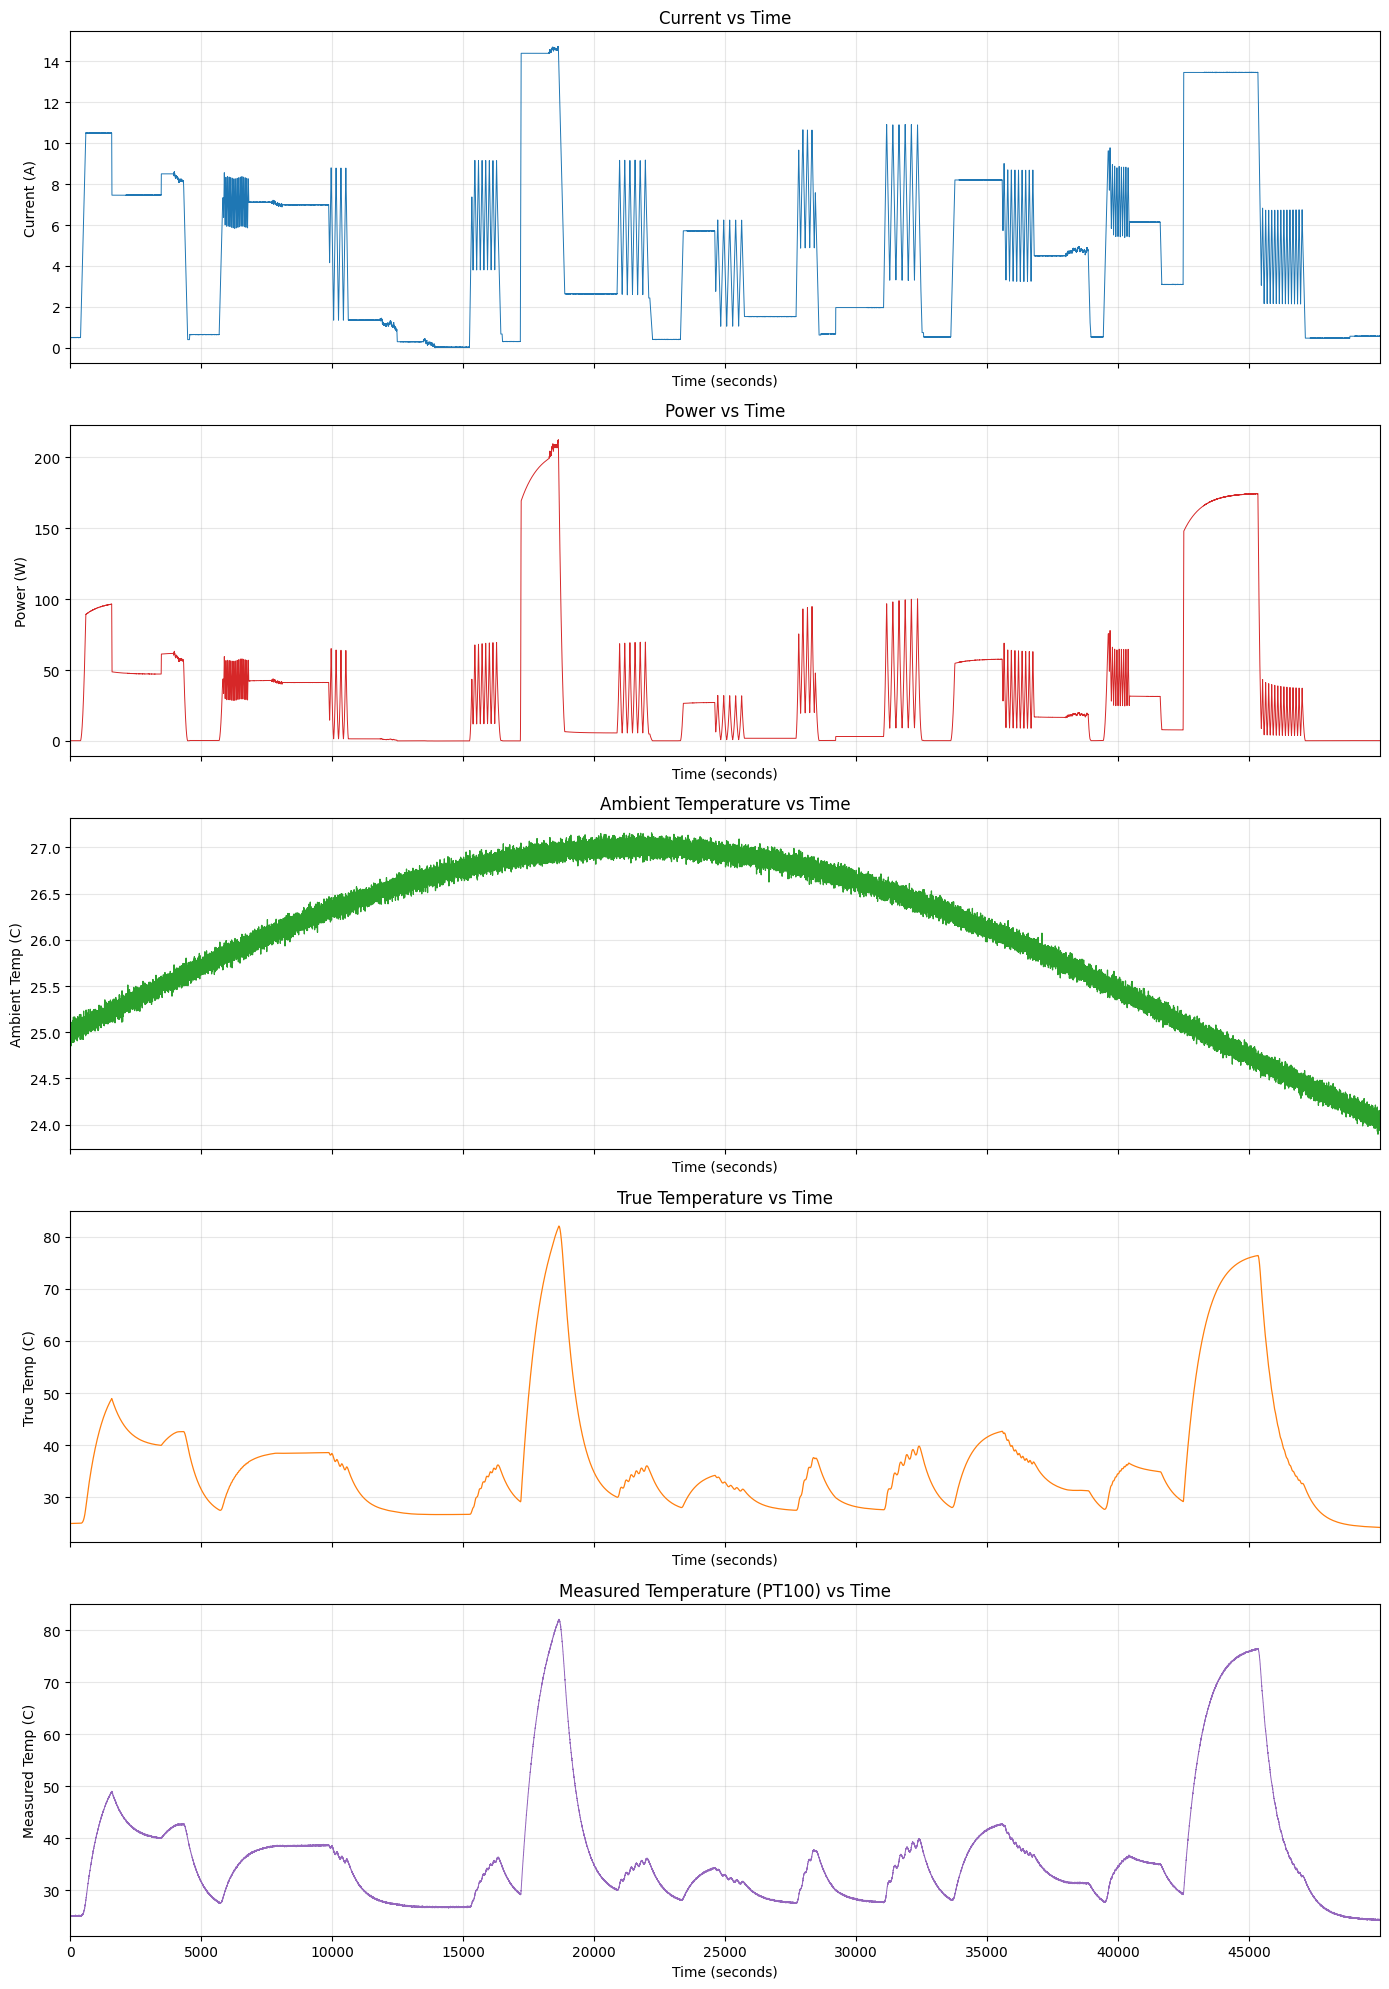

In [11]:
def format_time_axis(ax):
    """Apply a consistent elapsed-time-in-seconds x-axis format."""
    ax.set_xlabel("Time (seconds)")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(5000))
    ax.set_xlim(df["Time_s"].min(), df["Time_s"].max())
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(5, 1, figsize=(14, 20), sharex=True)

axes[0].plot(df["Time_s"], df["Current_A"], color="tab:blue", linewidth=0.7)
axes[0].set_ylabel("Current (A)")
axes[0].set_title("Current vs Time")
format_time_axis(axes[0])

axes[1].plot(df["Time_s"], df["Power_W"], color="tab:red", linewidth=0.7)
axes[1].set_ylabel("Power (W)")
axes[1].set_title("Power vs Time")
format_time_axis(axes[1])

axes[2].plot(df["Time_s"], df["AmbientTemperature_C"], color="tab:green", linewidth=0.9)
axes[2].set_ylabel("Ambient Temp (C)")
axes[2].set_title("Ambient Temperature vs Time")
format_time_axis(axes[2])

axes[3].plot(df["Time_s"], df["TrueTemperature_C"], color="tab:orange", linewidth=0.9)
axes[3].set_ylabel("True Temp (C)")
axes[3].set_title("True Temperature vs Time")
format_time_axis(axes[3])

axes[4].plot(df["Time_s"], df["MeasuredTemperature_C"], color="tab:purple", linewidth=0.7)
axes[4].set_ylabel("Measured Temp (C)")
axes[4].set_title("Measured Temperature (PT100) vs Time")
format_time_axis(axes[4])

plt.tight_layout()
plt.savefig("magnet_power_supply_overview.png", dpi=150)
plt.show()


### True vs Measured Temperature (overlay, zoomed window)

A closer look at a 5,000-second window shows the PT100 sensor's noise,
quantization steps, and small response lag relative to the true (physical)
temperature.


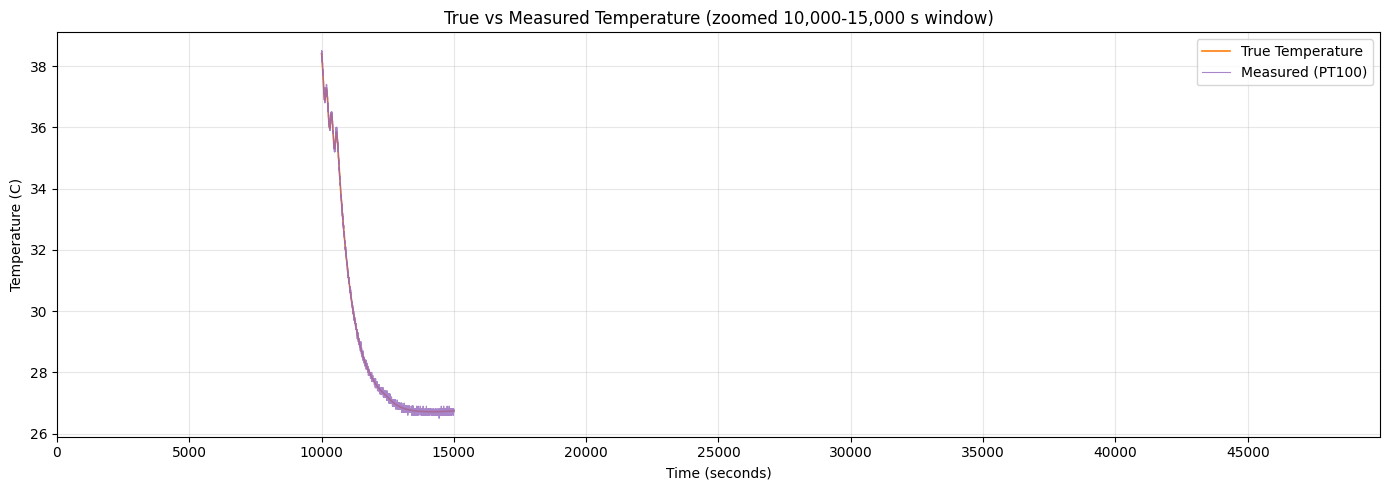

In [12]:
window = df[(df["Time_s"] >= 10_000) & (df["Time_s"] <= 15_000)]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(window["Time_s"], window["TrueTemperature_C"], label="True Temperature",
        color="tab:orange", linewidth=1.2)
ax.plot(window["Time_s"], window["MeasuredTemperature_C"], label="Measured (PT100)",
        color="tab:purple", linewidth=0.8, alpha=0.8)
ax.set_ylabel("Temperature (C)")
ax.set_title("True vs Measured Temperature (zoomed 10,000-15,000 s window)")
ax.legend()
format_time_axis(ax)
plt.tight_layout()
plt.show()


## 12. Summary

- Exactly **50,000** samples at **1 Hz**, elapsed-time indexed only (`Sample`, `Time_s`).
- Current generated by a **7-state FSM** (Idle / Ramp Up / Ramp Down / Constant
  Hold / Step Change / Random Walk / Load Cycling), bounded to 0–15 A with
  slew-rate limiting for realistic controller-like behavior.
- Temperature generated by a **first-order lumped thermal model**
  (`C dT/dt = I_eff^2 R(T) - (T - T_amb)/Rth`), Euler-integrated at 1 s steps,
  where **every sample is a function of the system's own previous state**
  (previous temperature, previous current, present current, ambient
  temperature) — giving the series genuine temporal/causal dependency.
- Resistance is temperature-dependent (copper temperature coefficient),
  coupling the electrical and thermal sub-models realistically.
- A virtual **PT100 sensor** adds response delay, Gaussian noise, and ADC
  quantization on top of the true temperature.
- A **fault injector** is fully implemented (fan failure, resistance increase,
  current spike, sensor offset/drift/freeze, intermittent cooling, thermal
  runaway) but **disabled** for this nominal-operation dataset.
- Output saved to `magnet_power_supply_dataset.csv`.

This notebook produces **only the simulated dataset** — no LSTM model,
preprocessing pipeline, or anomaly-detection logic is included here, per the
stated scope.
